# Tarea — Cinco gráficos con Matplotlib, Seaborn y Streamlit

Sesión 09 de Sistemas de Big Data: elegir el gráfico según lo que se quiere mostrar y construirlo con dos librerías estáticas. El dataset es el de viviendas de California (`housing.csv`, 20 640 distritos), el mismo del proyecto que sigue más abajo.

Cada gráfico se dibuja **dos veces en este cuaderno**: primero con Matplotlib y después con Seaborn. La página `app.py` repite esos cinco gráficos con Streamlit y deja elegir la librería.

## Qué gráfico responde a qué pregunta

| Gráfico | Pregunta | Por qué este tipo |
| --- | --- | --- |
| Barras | ¿Qué proximidad al océano tiene el precio medio más alto? | Compara un valor entre categorías. El eje empieza en 0 para no exagerar diferencias. La `n` recuerda que ISLAND son solo 5 distritos. |
| Histograma | ¿Cómo se reparte el ingreso medio? | Enseña la forma de una variable continua: cola a la derecha y corte en 15. |
| Dispersión | ¿El ingreso y el precio van juntos? | Relación entre dos variables numéricas. El color añade la categoría sin hacer otro gráfico. |
| Líneas | ¿El precio sube al pasar a tramos de ingreso más altos? | Los tramos tienen orden. La línea muestra esa tendencia mejor que unas barras sueltas. |
| Mapa de calor | ¿Qué variables numéricas se mueven a la vez? | Resume muchas relaciones. La paleta azul–rojo es divergente (de −1 a 1) y evita el par rojo–verde. |

No hay gráfico de tarta: las cinco categorías tienen tamaños muy distintos y comparar ángulos es peor que comparar las barras. Un solo color en las barras, porque la categoría ya está escrita en el eje.


In [1]:
# Mismas funciones que importa la página Streamlit (graficos.py).
# El cuaderno las incluye aquí para poder ejecutarse solo.

"""Cinco gráficos del dataset de viviendas, con Matplotlib y con Seaborn.

Cada función devuelve una figura del mismo gráfico en la librería pedida
(`matplotlib` o `seaborn`), para que el cuaderno y la página de Streamlit
enseñen la misma vista.
"""

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

ORDEN_PROXIMIDAD = ["INLAND", "<1H OCEAN", "NEAR OCEAN", "NEAR BAY", "ISLAND"]

# El ingreso del dataset está escalado: 3 equivale a unos 30 000 $ y el máximo
# está cortado en 15. Los cortes cubren ese rango, incluido el valor 15.0001.
TRAMOS_INGRESO = [0, 2, 3, 4, 5, 6, 8, 15.1]
ETIQUETAS_TRAMO = ["0-2", "2-3", "3-4", "4-5", "5-6", "6-8", "8-15"]

COLUMNAS_NUMERICAS = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income",
    "median_house_value",
]

ETIQUETAS = {
    "longitude": "Longitud",
    "latitude": "Latitud",
    "housing_median_age": "Edad media",
    "total_rooms": "Habitaciones",
    "total_bedrooms": "Dormitorios",
    "population": "Población",
    "households": "Hogares",
    "median_income": "Ingreso",
    "median_house_value": "Precio",
}

COLOR_SERIE = "#4C78A8"


def comprobar_libreria(libreria: str) -> str:
    nombre = libreria.strip().lower()
    if nombre not in {"matplotlib", "seaborn"}:
        raise ValueError("La librería debe ser 'matplotlib' o 'seaborn'.")
    return nombre


def aplicar_estilo(libreria: str) -> None:
    """Matplotlib se deja en su estilo base; Seaborn aplica su tema estadístico."""
    if libreria == "seaborn":
        sns.set_theme(style="whitegrid", palette="colorblind")
        return
    sns.reset_orig()
    plt.style.use("default")
    plt.rcParams.update(
        {
            "axes.grid": True,
            "grid.alpha": 0.35,
            "axes.axisbelow": True,
            "figure.facecolor": "white",
            "axes.facecolor": "white",
            "font.size": 11,
            "axes.titlesize": 13,
        }
    )


def formatear_precio(eje) -> None:
    eje.set_major_formatter(mticker.FuncFormatter(lambda valor, _pos: f"{valor / 1000:.0f} mil $"))


def precio_medio_por_proximidad(df: pd.DataFrame) -> pd.DataFrame:
    conteo = df["ocean_proximity"].value_counts()
    presentes = [categoria for categoria in ORDEN_PROXIMIDAD if categoria in conteo.index]
    resumen = (
        df.groupby("ocean_proximity", as_index=False)["median_house_value"]
        .mean()
        .rename(columns={"median_house_value": "precio_medio"})
    )
    resumen["ocean_proximity"] = pd.Categorical(
        resumen["ocean_proximity"], categories=presentes, ordered=True
    )
    resumen = resumen.sort_values("ocean_proximity")
    resumen["n"] = resumen["ocean_proximity"].astype(str).map(conteo).astype(int)
    # El recuento va en la etiqueta: ISLAND solo tiene 5 distritos y su media
    # no debe leerse como si pesara lo mismo que INLAND.
    resumen["etiqueta"] = resumen.apply(
        lambda fila: f"{fila['ocean_proximity']}  (n={fila['n']})", axis=1
    )
    return resumen


def precio_medio_por_tramo(df: pd.DataFrame) -> pd.DataFrame:
    trabajo = df.copy()
    trabajo["tramo_ingreso"] = pd.cut(
        trabajo["median_income"],
        bins=TRAMOS_INGRESO,
        labels=ETIQUETAS_TRAMO,
        include_lowest=True,
    )
    resumen = (
        trabajo.groupby("tramo_ingreso", observed=True)["median_house_value"]
        .mean()
        .reset_index()
        .rename(columns={"median_house_value": "precio_medio"})
    )
    resumen["tramo_ingreso"] = resumen["tramo_ingreso"].astype(str)
    return resumen


def matriz_correlacion(df: pd.DataFrame) -> pd.DataFrame | None:
    columnas = [columna for columna in COLUMNAS_NUMERICAS if df[columna].nunique(dropna=True) > 1]
    if len(columnas) < 2:
        return None
    return df[columnas].corr()


def _titulo(ax, texto: str) -> None:
    ax.set_title(texto, fontsize=13, pad=12)


def _sin_marcos(ax) -> None:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


In [2]:
from pathlib import Path

ruta = Path("housing.csv")
if not ruta.exists():
    ruta = Path("/content/housing.csv")
if not ruta.exists():
    raise FileNotFoundError(
        "No se encuentra housing.csv. Déjalo en la misma carpeta que este cuaderno."
    )

housing = pd.read_csv(ruta)
print(f"Distritos: {len(housing)}")
print(housing["ocean_proximity"].value_counts().to_string())


Distritos: 20640
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5


### 1. Barras — comparación

La media del precio mediano del distrito pasa de unos **125 mil $** en el interior a unos **240–259 mil $** junto a la costa. ISLAND queda en unos **380 mil $**, pero solo hay **5** distritos: la etiqueta `n` evita leer esa barra como si pesara igual que las demás.

El eje horizontal empieza en 0. Matplotlib y Seaborn dibujan la misma media, ya calculada, para que el gráfico sea el mismo.


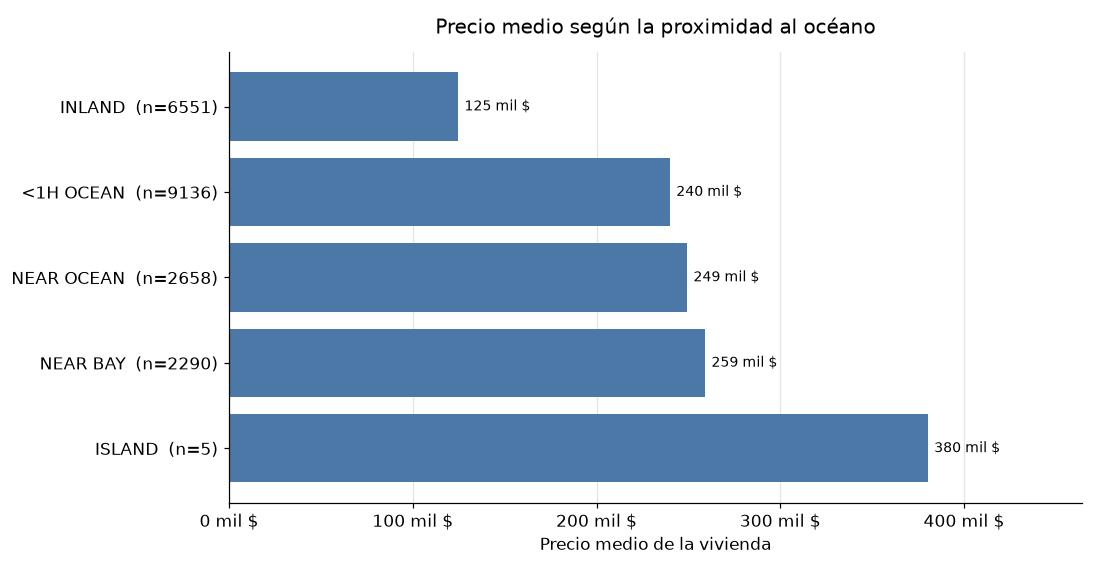

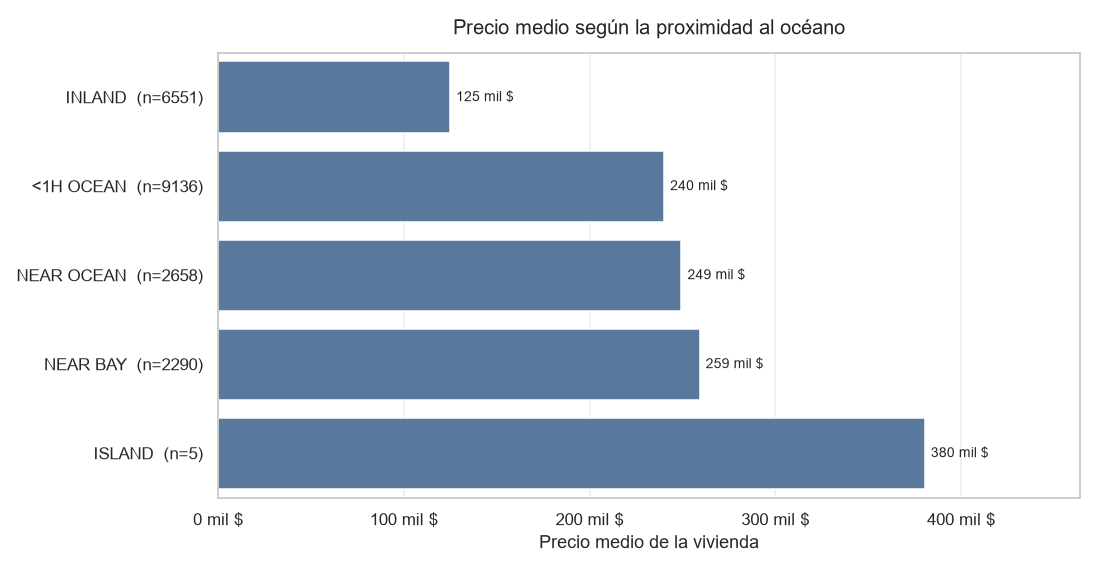

In [3]:
def figura_barras(df: pd.DataFrame, libreria: str) -> plt.Figure:
    """Comparación: precio medio de cada proximidad al océano."""
    libreria = comprobar_libreria(libreria)
    aplicar_estilo(libreria)
    resumen = precio_medio_por_proximidad(df)
    fig, ax = plt.subplots(figsize=(10, 5.2))
    etiquetas_valor = [f"{valor / 1000:.0f} mil $" for valor in resumen["precio_medio"]]
    # Un solo color: la categoría ya está en el eje. Otro color por barra
    # no añadiría información.
    if libreria == "matplotlib":
        barras = ax.barh(resumen["etiqueta"], resumen["precio_medio"], color=COLOR_SERIE)
        ax.bar_label(barras, labels=etiquetas_valor, padding=4, fontsize=9)
        # barh coloca la primera categoría abajo; Seaborn la coloca arriba.
        ax.invert_yaxis()
        _sin_marcos(ax)
    else:
        sns.barplot(
            data=resumen,
            x="precio_medio",
            y="etiqueta",
            order=resumen["etiqueta"].tolist(),
            color=COLOR_SERIE,
            ax=ax,
        )
        ax.bar_label(ax.containers[0], labels=etiquetas_valor, padding=4, fontsize=9)

    _titulo(ax, "Precio medio según la proximidad al océano")
    ax.set_xlabel("Precio medio de la vivienda")
    ax.set_ylabel("")
    ax.set_xlim(0, resumen["precio_medio"].max() * 1.22)
    formatear_precio(ax.xaxis)
    ax.grid(True, axis="x", alpha=0.35)
    ax.grid(False, axis="y")
    fig.tight_layout()
    return fig

figura_barras(housing, "matplotlib")
plt.show()
figura_barras(housing, "seaborn")
plt.show()


### 2. Histograma — distribución

El ingreso medio del dataset no está en dólares: está escalado y **cortado en 15** (15 equivale a los ingresos más altos). Casi todos los distritos caen entre 2 y 5, la cola se alarga hacia la derecha y el corte deja una barra pequeña al final.

Los dos histogramas usan los mismos bordes de intervalo, de 0 a 16, para que se puedan comparar a simple vista.


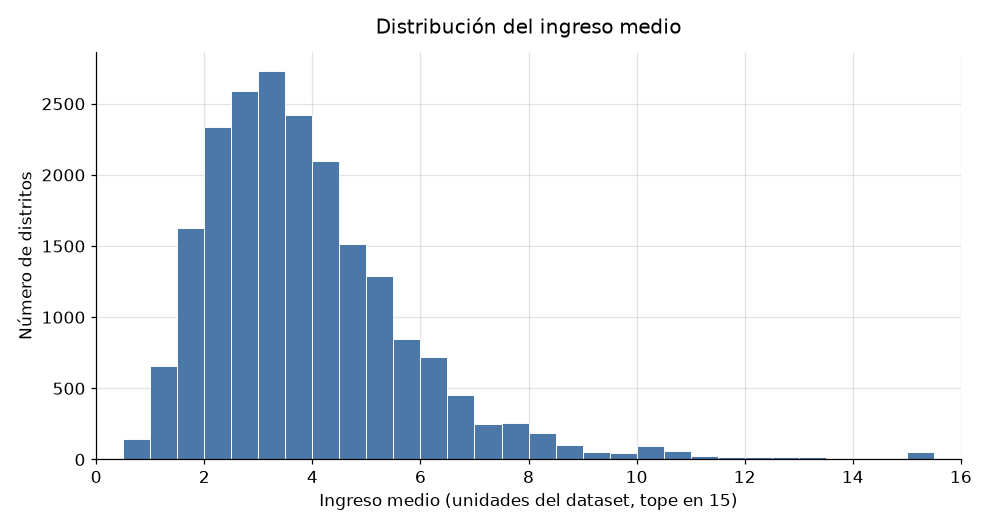

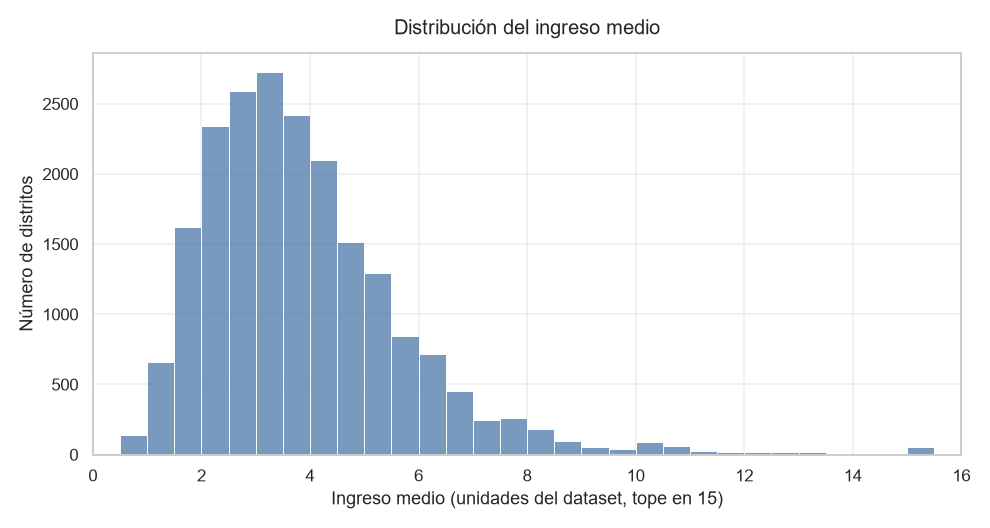

In [4]:
def figura_histograma(df: pd.DataFrame, libreria: str) -> plt.Figure:
    """Distribución: forma del ingreso medio, con los mismos cortes en ambas librerías."""
    libreria = comprobar_libreria(libreria)
    aplicar_estilo(libreria)
    # Bordes fijos para que Matplotlib y Seaborn partan el eje igual.
    cortes = np.linspace(0, 16, 33)
    fig, ax = plt.subplots(figsize=(9, 4.8))

    if libreria == "matplotlib":
        ax.hist(
            df["median_income"],
            bins=cortes,
            color=COLOR_SERIE,
            edgecolor="white",
            linewidth=0.6,
        )
        _sin_marcos(ax)
    else:
        sns.histplot(
            data=df,
            x="median_income",
            bins=cortes,
            color=COLOR_SERIE,
            edgecolor="white",
            linewidth=0.6,
            ax=ax,
        )

    _titulo(ax, "Distribución del ingreso medio")
    ax.set_xlabel("Ingreso medio (unidades del dataset, tope en 15)")
    ax.set_ylabel("Número de distritos")
    ax.set_xlim(0, 16)
    fig.tight_layout()
    return fig

figura_histograma(housing, "matplotlib")
plt.show()
figura_histograma(housing, "seaborn")
plt.show()


### 3. Dispersión — relación entre dos variables

Cada punto es un distrito. El precio sube con el ingreso (correlación de **0,69**). También se ven dos topes de los datos: el precio no pasa de **500 000 $** (línea horizontal) y el ingreso no pasa de **15**.

El interior (INLAND) se concentra en precios bajos. La leyenda queda fuera del área de puntos para no tapar esa línea de 500 000 $.


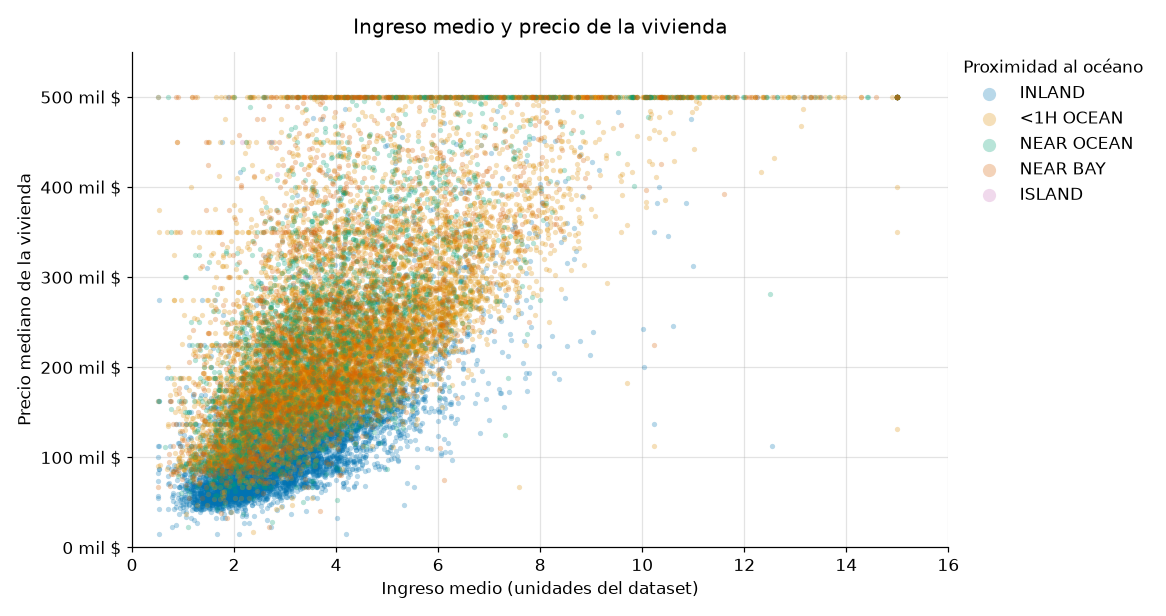

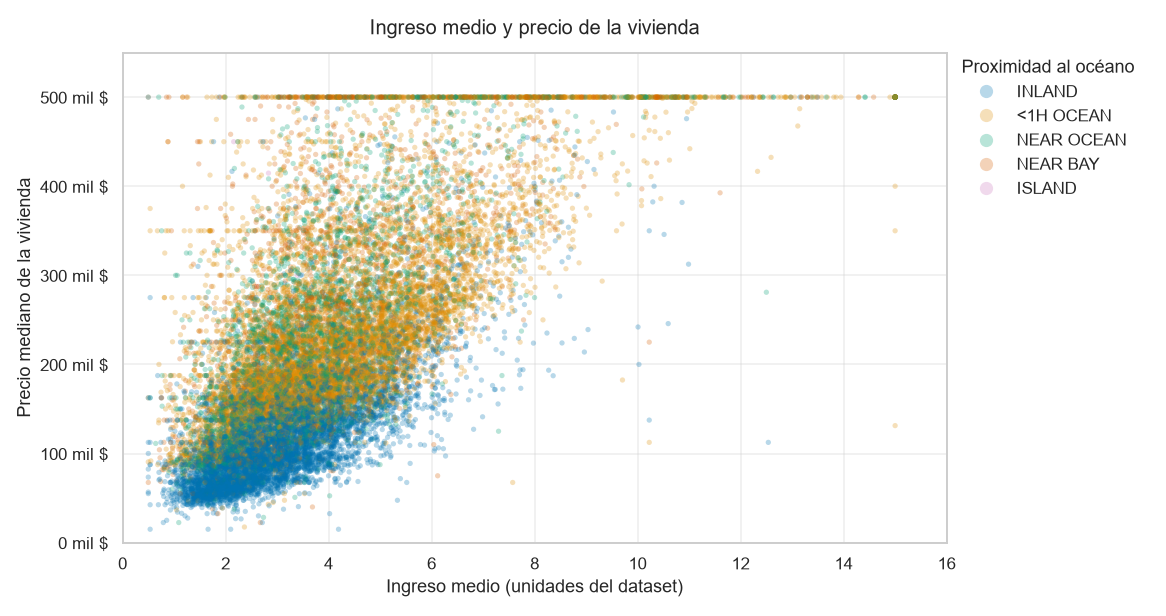

In [5]:
def figura_dispersion(df: pd.DataFrame, libreria: str) -> plt.Figure:
    """Relación: ingreso medio frente al precio, con la proximidad en el color."""
    libreria = comprobar_libreria(libreria)
    aplicar_estilo(libreria)
    presentes = [
        categoria for categoria in ORDEN_PROXIMIDAD if categoria in set(df["ocean_proximity"])
    ]
    paleta = dict(zip(presentes, sns.color_palette("colorblind", n_colors=len(presentes))))
    fig, ax = plt.subplots(figsize=(10.6, 5.6))

    if libreria == "matplotlib":
        for categoria in presentes:
            grupo = df[df["ocean_proximity"] == categoria]
            ax.scatter(
                grupo["median_income"],
                grupo["median_house_value"],
                s=12,
                alpha=0.28,
                linewidths=0,
                label=categoria,
                color=paleta[categoria],
            )
        _sin_marcos(ax)
    else:
        sns.scatterplot(
            data=df,
            x="median_income",
            y="median_house_value",
            hue="ocean_proximity",
            hue_order=presentes,
            palette=paleta,
            s=12,
            alpha=0.28,
            linewidth=0,
            ax=ax,
        )

    # Fuera del área de puntos para no tapar el tope de 500 000 $.
    ax.legend(
        title="Proximidad al océano",
        markerscale=2.5,
        frameon=False,
        loc="upper left",
        bbox_to_anchor=(1.01, 1),
        borderaxespad=0,
    )

    _titulo(ax, "Ingreso medio y precio de la vivienda")
    ax.set_xlabel("Ingreso medio (unidades del dataset)")
    ax.set_ylabel("Precio mediano de la vivienda")
    ax.set_xlim(0, 16)
    ax.set_ylim(0, 550_000)
    formatear_precio(ax.yaxis)
    fig.tight_layout()
    return fig

figura_dispersion(housing, "matplotlib")
plt.show()
figura_dispersion(housing, "seaborn")
plt.show()


### 4. Líneas — tendencia

Aquí el ingreso se agrupa en tramos ordenados y se dibuja el precio medio de cada tramo. La media sube en todos ellos, de unos **112 mil $** (ingreso 0–2) a unos **461 mil $** (ingreso 8–15), sin ningún retroceso.

Una línea encaja porque el eje horizontal tiene orden. El eje vertical empieza en 0.


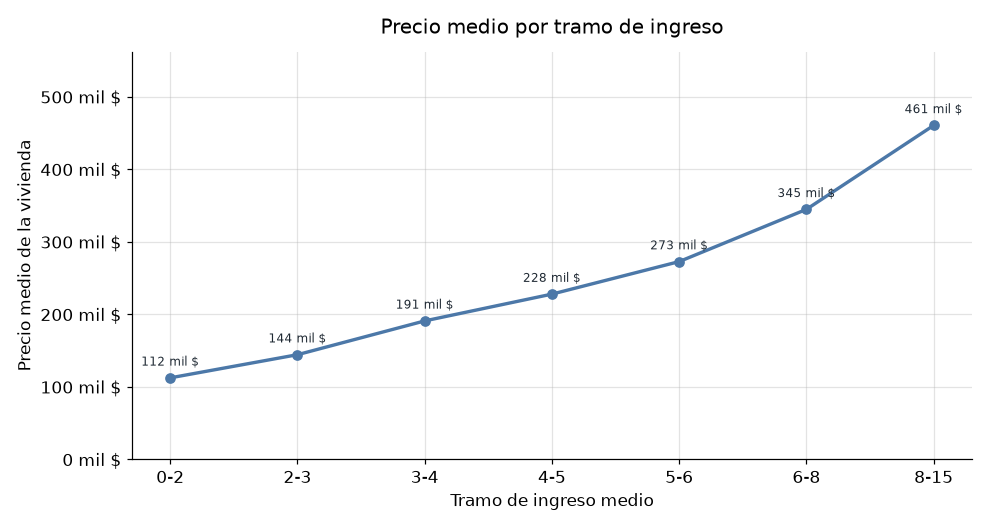

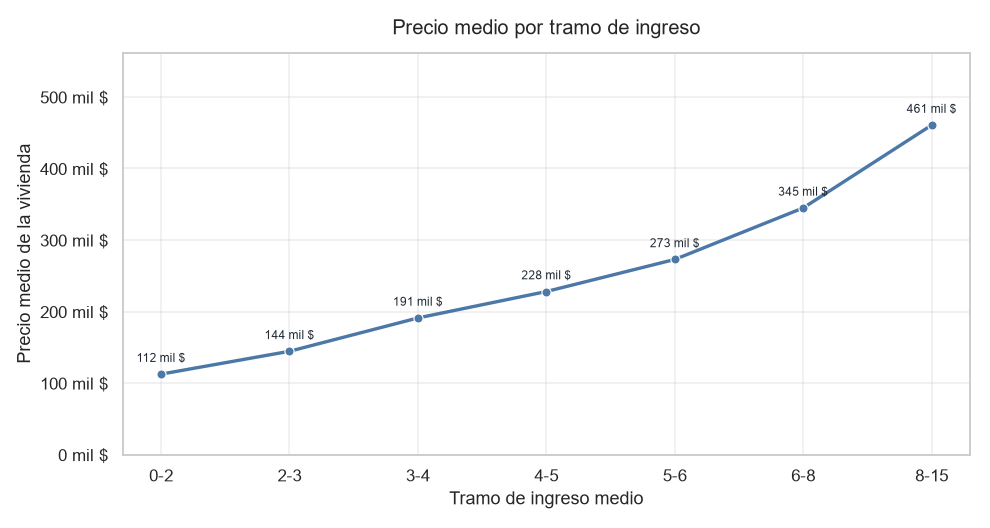

In [6]:
def figura_lineas(df: pd.DataFrame, libreria: str) -> plt.Figure:
    """Tendencia: el precio medio sube al pasar a tramos de ingreso más altos."""
    libreria = comprobar_libreria(libreria)
    aplicar_estilo(libreria)
    resumen = precio_medio_por_tramo(df)
    fig, ax = plt.subplots(figsize=(9, 4.8))

    if libreria == "matplotlib":
        ax.plot(
            resumen["tramo_ingreso"],
            resumen["precio_medio"],
            marker="o",
            linewidth=2.2,
            color=COLOR_SERIE,
        )
        _sin_marcos(ax)
    else:
        sns.lineplot(
            data=resumen,
            x="tramo_ingreso",
            y="precio_medio",
            marker="o",
            linewidth=2.2,
            color=COLOR_SERIE,
            ax=ax,
        )

    for tramo, valor in zip(resumen["tramo_ingreso"], resumen["precio_medio"]):
        ax.annotate(
            f"{valor / 1000:.0f} mil $",
            (tramo, valor),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center",
            fontsize=8,
            color="#1F2933",
        )

    _titulo(ax, "Precio medio por tramo de ingreso")
    ax.set_xlabel("Tramo de ingreso medio")
    ax.set_ylabel("Precio medio de la vivienda")
    if not resumen.empty:
        ax.set_ylim(0, resumen["precio_medio"].max() * 1.22)
    formatear_precio(ax.yaxis)
    fig.tight_layout()
    return fig

figura_lineas(housing, "matplotlib")
plt.show()
figura_lineas(housing, "seaborn")
plt.show()


### 5. Mapa de calor — relación entre muchas variables

Cada celda es la correlación de Pearson entre dos columnas numéricas. El ingreso es, con diferencia, la variable que más acompaña al precio (**0,69**). Habitaciones, dormitorios, población y hogares van muy juntos entre sí: miden el tamaño del distrito y aportan poca información nueva sobre el precio.

Los números usan coma decimal. En las celdas más fuertes el texto pasa a blanco para que se pueda leer.


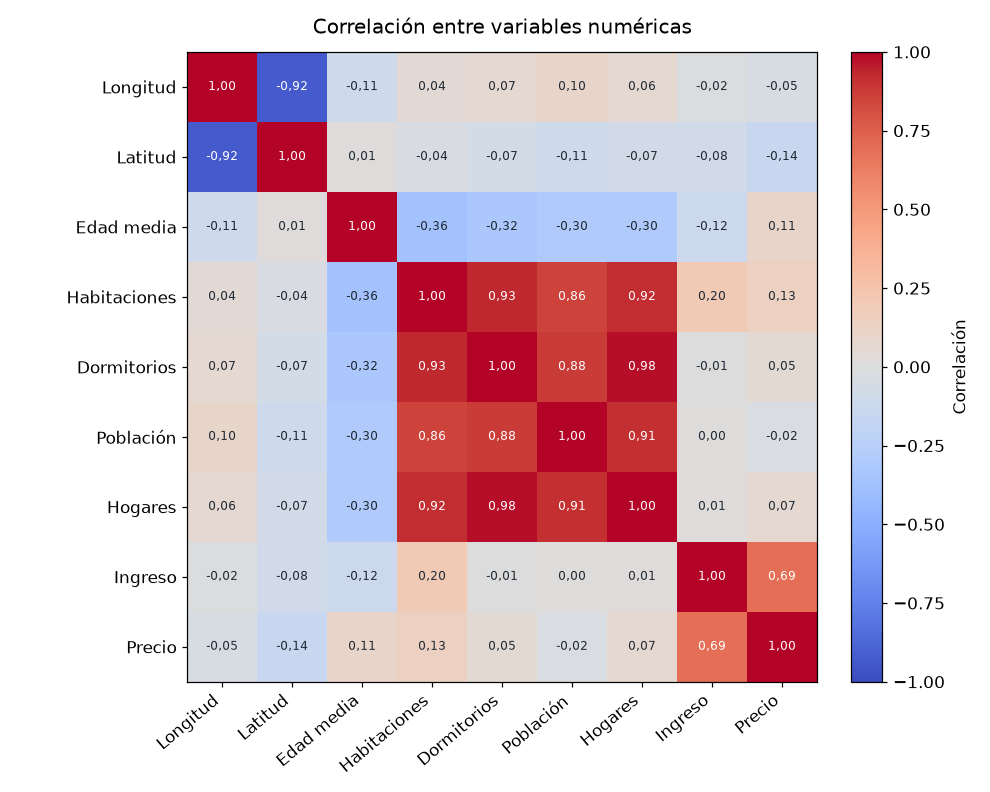

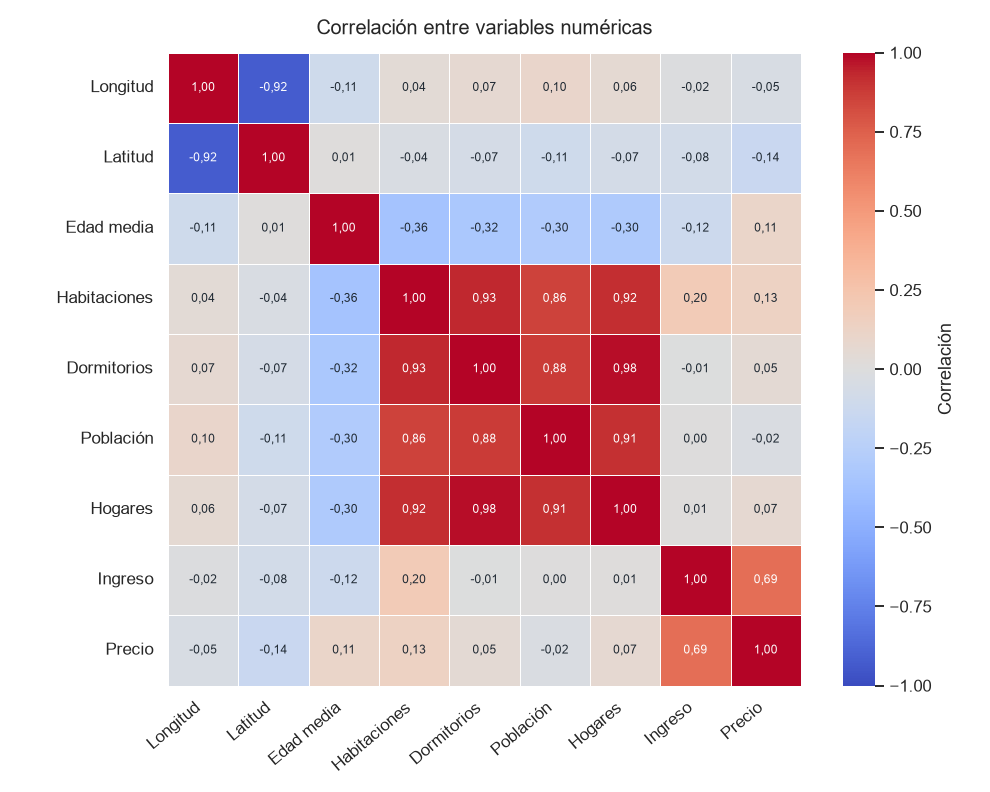

In [7]:
def figura_mapa_calor(df: pd.DataFrame, libreria: str) -> plt.Figure:
    """Relación entre muchas variables: matriz de correlación."""
    libreria = comprobar_libreria(libreria)
    aplicar_estilo(libreria)
    matriz = matriz_correlacion(df)
    fig, ax = plt.subplots(figsize=(9, 7.2))

    if matriz is None:
        ax.text(
            0.5,
            0.5,
            "No hay variación suficiente para calcular correlaciones.",
            ha="center",
            va="center",
            transform=ax.transAxes,
        )
        ax.axis("off")
        _titulo(ax, "Correlación entre variables numéricas")
        fig.tight_layout()
        return fig

    etiquetas = [ETIQUETAS[columna] for columna in matriz.columns]
    anotaciones = matriz.map(lambda valor: f"{valor:.2f}".replace(".", ","))

    if libreria == "matplotlib":
        imagen = ax.imshow(matriz.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
        ax.set_xticks(range(len(etiquetas)), labels=etiquetas, rotation=40, ha="right")
        ax.set_yticks(range(len(etiquetas)), labels=etiquetas)
        for fila in range(matriz.shape[0]):
            for columna in range(matriz.shape[1]):
                valor = matriz.iloc[fila, columna]
                ax.text(
                    columna,
                    fila,
                    anotaciones.iloc[fila, columna],
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="white" if abs(valor) >= 0.55 else "#1F2933",
                )
        ax.set_aspect("equal")
        fig.colorbar(imagen, ax=ax, fraction=0.046, pad=0.04).set_label("Correlación")
    else:
        sns.heatmap(
            matriz,
            annot=anotaciones,
            fmt="",
            cmap="coolwarm",
            vmin=-1,
            vmax=1,
            square=True,
            linewidths=0.4,
            linecolor="white",
            cbar_kws={"label": "Correlación"},
            xticklabels=etiquetas,
            yticklabels=etiquetas,
            annot_kws={"fontsize": 8},
            ax=ax,
        )
        ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
        for texto in ax.texts:
            try:
                valor = float(texto.get_text().replace(",", "."))
            except ValueError:
                continue
            texto.set_color("white" if abs(valor) >= 0.55 else "#1F2933")

    ax.grid(False)
    _titulo(ax, "Correlación entre variables numéricas")
    fig.tight_layout()
    return fig

figura_mapa_calor(housing, "matplotlib")
plt.show()
figura_mapa_calor(housing, "seaborn")
plt.show()


### Página con Streamlit

Esos mismos cinco gráficos están en `app.py`, que importa `graficos.py`. Desde esta carpeta:

```bash
python -m pip install -r requirements.txt
python -m streamlit run app.py
```

En la barra lateral se elige **Matplotlib** o **Seaborn** y se puede acotar la proximidad al océano y el ingreso medio. Barras, histograma, dispersión, línea y mapa de calor se recalculan con el mismo subconjunto.

---

## Proyecto de machine learning

Debajo sigue el cuaderno original del proyecto de precios. Para esta tarea bastan las celdas de arriba. El proyecto de abajo monta Google Drive y no hace falta ejecutarlo para ver los gráficos.


# Proyecto completo de machine learning - Inversiones inmobiliarias

## Imágen general / problema a resolver

La empresa **Alan Turing Real State** nos ha contratado para realizar un modelo de los precios de las viviendas en California.

Este modelo debe predecir el precio medio de las viviendas de un distrito en función de los datos que tenemos de él.

La finalidad es encontrar oportunidades de inversión.

<img src="https://drive.google.com/uc?id=1gjmoa33WGkwZs5vew3agyks2ZzQih5Uf" height="350px">

Vamos a tener los siguientes datos sobre los distritos:

* Longitud
* Latitud
* Edad media de los inmuebles
* Total de habitaciones
* Total de dormitorios
* Población
* Número de viviendas
* Media de ingresos
* Proximidad a la costa
* **Precio**

Los datos están etiquetados y queremos saber un valor concreto, por tanto, se trata de un sistema **supervisado**.

Vamos a predecir un valor, por tanto, estamos ante un problema de **regresión**, en concreto de **regresión multiple**, ya que tenemos muchas características para hacer la predicción.

En un problema de regreión hay varias medidas que pueden dar el rendimiento. Una de ellas es la **raiz del error cuadrático medio**, en inglés, **Root Mean Square Error (RMSE)**

$RMSE(X, h)=\sqrt{{\frac{1}{m}}\sum_{i=1}^m(h(x^{(i)})-y^{(i)})^2}$

$m$ es el número de instancias (casos)

$x^{(i)}$ es el vector de todas las características (sin incluir la etiqueta) de la $i-ésima$ instancia e¡del dataset.

$y^{(i)}$ es la salida esperada para esa instancia.

Por ejemplo, si un distrito del dataset está localizado en una longitud de -18.29º, una latitud de 33.91º, tiene 1416 habitantes con una media de ingresos de 38372 dólares y el valor medio de la vivienda es de 156400 dólares (ignorando otras caracterísitcas de momento), entonces:

$x^{(1)} =
\left (
  \begin{array}{r}
    -18.29\\
    33.91\\
    1416\\
    38372\\
  \end{array}
\right )
$

$y^{(1)} = 156400$

$X$ es la matriz que contiene las características del dataset.

$X =
\left (
  \begin{array}{cccc}
    -18.29 & 33.91 & 1416 & 38372\\
    . & . & .& . &\\
    . & . & .& . &\\
    . & . & .& . &\\
  \end{array}
\right )
$

$h$ es la función de predicción, también llamada hipótesis.

Cuando al sistema se le dan las características de una instancia x^{(i)}, su salida predice un valor $\hat{y}^{(i)}=h(x^{(i)})$

Por ejemplo, si el sistema predice el precio medio de la vivienda para el primer distrito es 158400, entonces $\hat{y}^{(i)}=h(x^{(i)})=158400$

El error absoluto de la predicción para este distrito es de $\hat{y}^{(1)}-y^{(1)}=158400-156400=2000$

## Obtención de datos

Los datos están contenidos en `housing.csv` (en Moodle)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
# Cargamos los datos en un dataframe de Pandas
housing = pd.read_csv("/content/drive/MyDrive/housing.csv")

Mounted at /content/drive


## Exploración y visualización de los datos

In [ ]:
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


El atributo `ocean_proximity` es el único que no es de tipo `float`. Se trata de una cadena de carácteres.

El atributo `total_bedrooms` presenta muchos valores nulos.

In [ ]:
# Valores que puede tener ocean_proximity

housing["ocean_proximity"].unique()

array(['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND'],
      dtype=object)

¿Cuántos casos hay de cada tipo? ¿Cuántos tienen el vaor `NEAR_BAY`?, ¿cuántos `<1H OCEAN`?, etc.

In [ ]:
housing["ocean_proximity"].value_counts()

,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


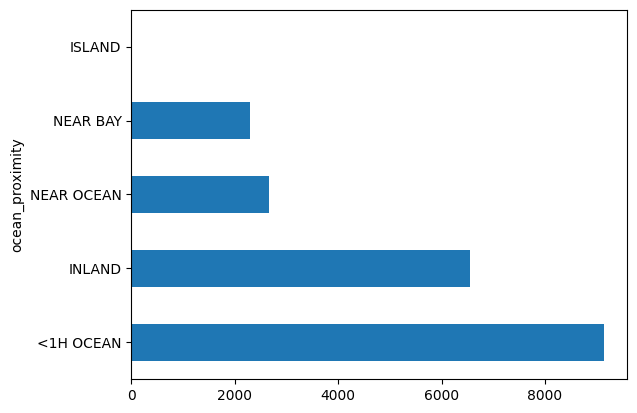

In [ ]:
housing["ocean_proximity"].value_counts().plot(kind="barh")
plt.show()

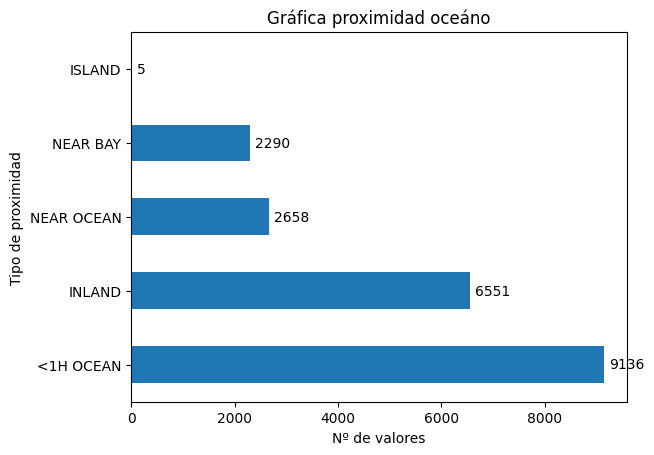

In [ ]:
# Añade etiquetas con los valores numéricos sobre cada barra
ax = housing["ocean_proximity"].value_counts().plot(kind="barh")
plt.title("Gráfica proximidad oceáno")
plt.xlabel("Nº de valores")
plt.ylabel("Tipo de proximidad")
ax.bar_label(ax.containers[0], padding=4)
plt.show()

* ax.containers -> lista de grupos de barras
* ax.containers[1] -> el iésimo grupo (un BarContainer)
* BarContainer -> iterable de rectángulos (Rectangle), que son las barras

In [ ]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


El 25% de los distritos tiene una edad media inferior a 18 años.

¿Qué precio tiene el distrito más caro? 500001
Investigando sobre el dataset, hemos averiguado que se han topado a próposito los distritos con un media de más de medio millón.

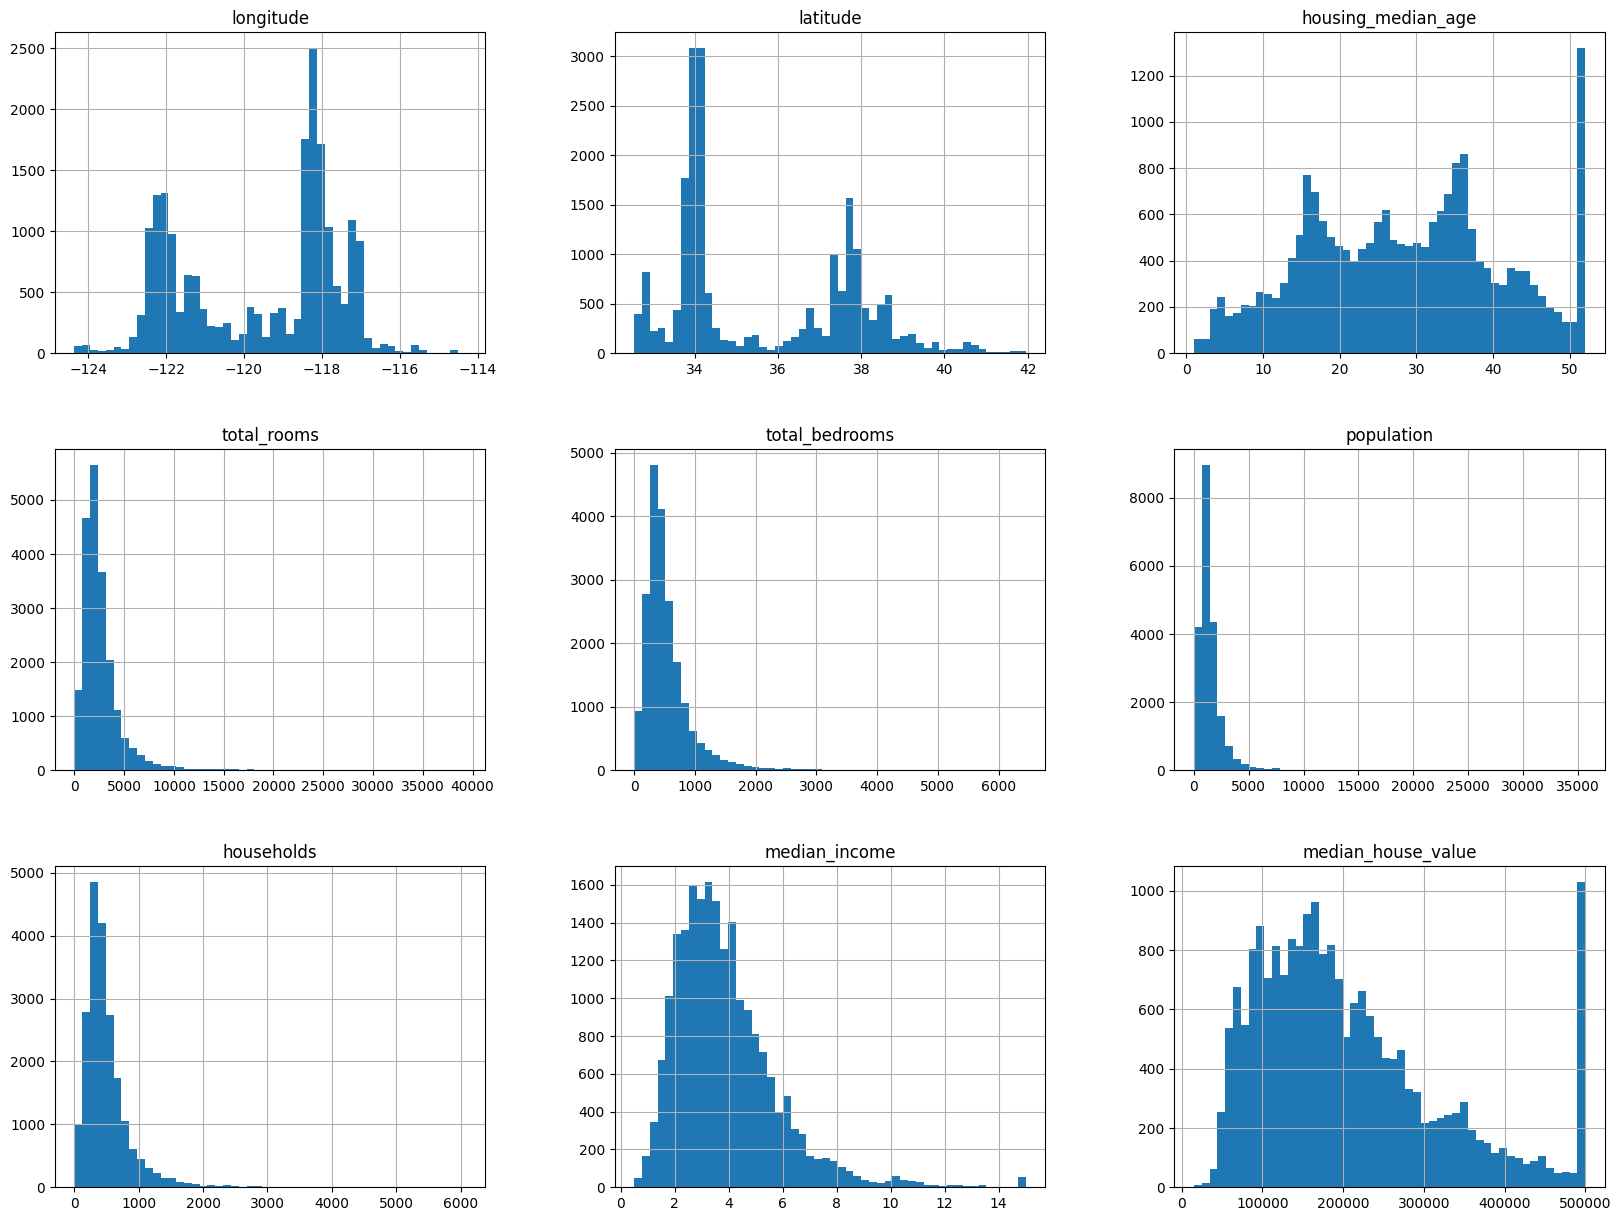

In [ ]:
# Histogramas de todos los datos numéricos
housing.hist(bins=50, figsize=(20,15))
plt.show()

¿Qué podemos observar en los histogramas?

1. La media de edad y el precio están limitados.
2. Varios histogramas tienen una cola alargada (se extienden mucho más a la derecha que a la izquierda).
3. Los atributos tiene escalas muy diferentes.
4. Los ingresos no parecen estar expresados en dólares. Después de hablar con le equipo que recopiló los datos, sabemos que los ingresos han sido escalados y limitados a 15 para los ingresos más altos y a 0'5 para los más bajos.

## Datos geográficos

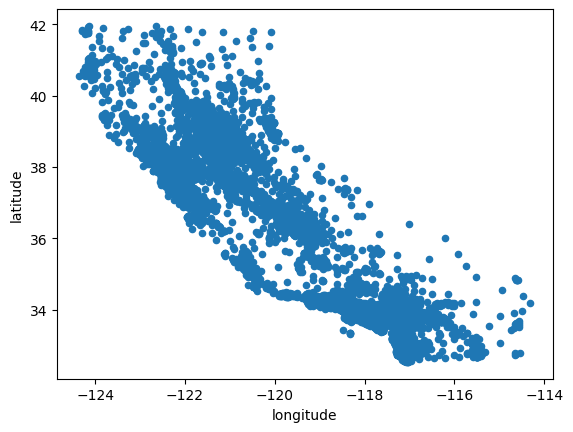

In [ ]:
housing.plot(kind="scatter", x="longitude", y="latitude")
plt.show()

Con puntos semitransparentes se pueden apreciar las zonas con diferente densidad.

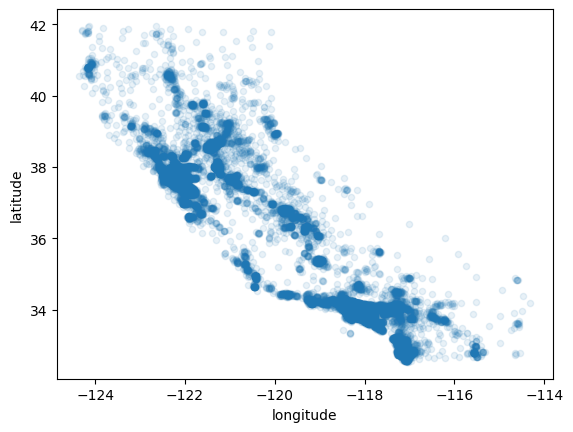

In [ ]:
housing.plot(kind="scatter", x="longitude", y="latitude", alpha=0.1)
plt.show()

Vamos a representar la población del distrito mediante el radio de cada circulito, mientras que usaremos el color para representar el precio.

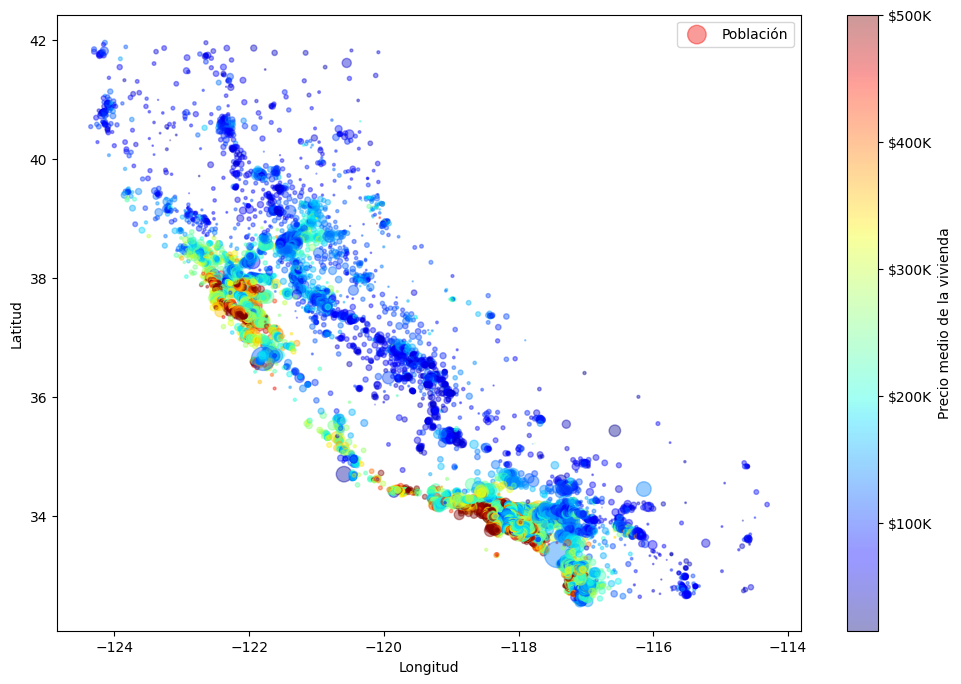

In [ ]:
import matplotlib.ticker as ticker

plt.figure(figsize=(12, 8))

graphic = plt.scatter(
  x=housing["longitude"], y=housing["latitude"], alpha=0.4,
  s=housing["population"]/100, label="Población",
  c=housing["median_house_value"], cmap="jet"
)

plt.xlabel("Longitud")
plt.ylabel("Latitud")

cbar = plt.colorbar(graphic)
cbar.set_label("Precio medio de la vivienda")

cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda value, _: f"${value/1000:.0f}K"))

plt.legend()
plt.show()

## Correlaciones

In [ ]:
# Matriz de correlaciones

housing_sin_ocean_proximity = housing.drop("ocean_proximity", axis=1)
corr_matrix = housing_sin_ocean_proximity.corr()
corr_matrix

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


In [ ]:
# Relación de cada uno de los atributos con el precio medio de la vivienda

corr_matrix["median_house_value"].sort_values(ascending=False)

,median_house_value
median_house_value,1.000000
median_income,0.688075
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049686
population,-0.024650
longitude,-0.045967
latitude,-0.144160


Vemos que hay una correlación clara entre el precio de la vivienda en un distrito y la media de ingresos en ese distrito.

In [ ]:
from pandas.plotting import scatter_matrix

En las diagonales, en lugar de salir una líne recta de la forma $y=x$ que no sería muy útil, saca el histograma del atributo.

Se ve claramente la correlación entre `median_income` y `median_house_value`.

Vamos a mostrar esa gráfica por separado.

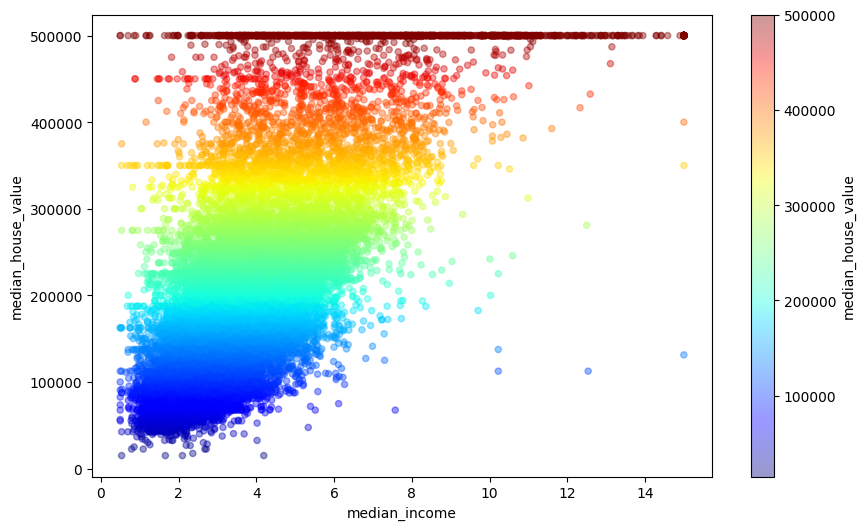

In [ ]:
housing.plot(kind="scatter", x="median_income", y="median_house_value", alpha=0.4, figsize=(10, 6), c="median_house_value", cmap="jet", colorbar=True)
plt.show()

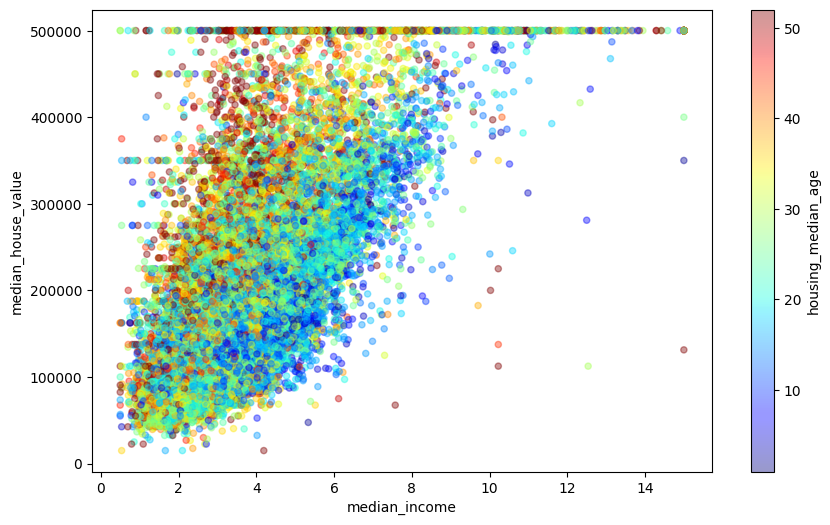

In [ ]:
housing.plot(kind="scatter", x="median_income", y="median_house_value", alpha=0.4, figsize=(10, 6), c="housing_median_age", cmap="jet", colorbar=True)
plt.show()

Para ver las relaciones entre atributos, podemos usar también un mapa de calor.

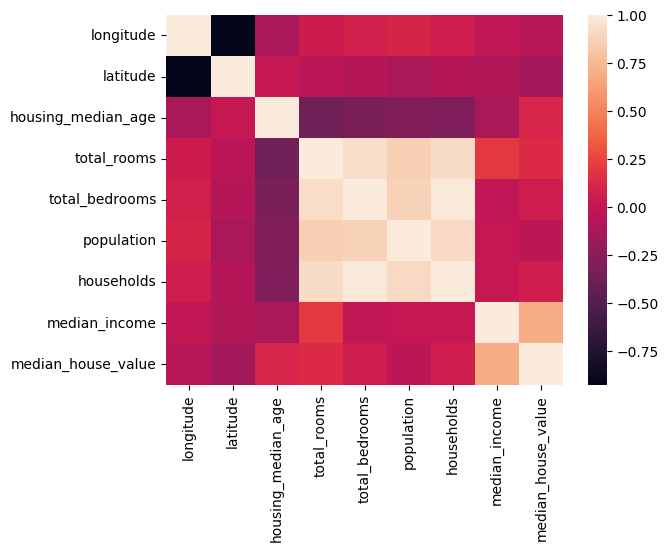

In [ ]:
sns.heatmap(corr_matrix)
plt.show()

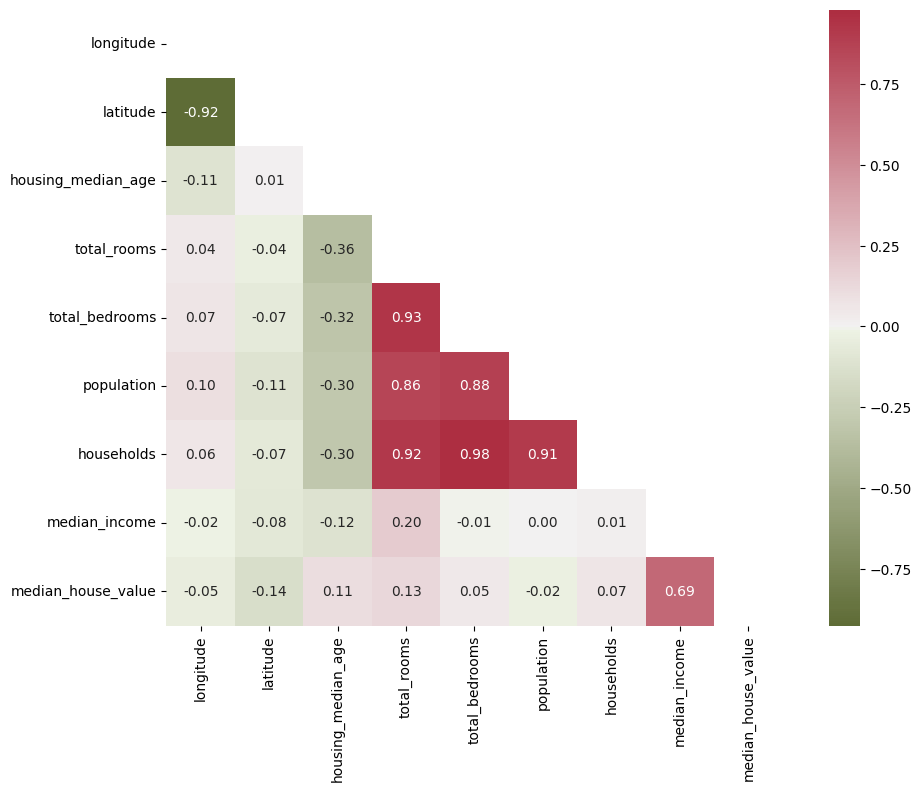

In [ ]:
# Igual pero más bonito

# Crea una máscara triangular superior para la matriz de correlación corr_matrix.
# np.ones_like(corr_matrix, dtype=bool) crea una matriz del mismo tamaño que corr_matrix, donde todos los elementos son True (1).
# np.triu() extrae la parte triangular superior de esta matriz, es decir, los valores por encima de la diagonal principal (incluida la diagonal).
# El resultado es una máscara donde los elementos en la parte triangular inferior son False y los elementos en la triangular superior son True.
# Esta máscara es para ocultar la parte triangular superior de la matriz de correlación, ya que es simétrica.

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))


# Crea una paleta personalizada
# 100, 7: Define los dos extremos de la paleta, que diverge desde un color cerca del índice 100 hasta uno cerca del índice 7 (usa el sistema HSL, 100 y 7 son los valores de matiz, o sea H que es el tono).
# s=75, l=40: Controlan la saturación (s) y la luminosidad (l) de los colores.
# n=5: El número de colores que se usarán en la paleta.
# center="light": El centro de la paleta será un color más claro, que es útil para enfatizar valores cerca de cero en una escala divergente.
# as_cmap=True: Indica que esta paleta será usada como un colormap (mapa de colores) en el gráfico.
cmap = sns.diverging_palette(100, 7, s=75, l=40, n=5, center="light", as_cmap=True)


plt.figure(figsize=(12, 8))

# mask=mask: Aplica la máscara creada anteriormente para ocultar la parte triangular superior de la matriz.
# center=0: Centra los valores en 0, útil para mapas de calor de matrices de correlación, donde los valores pueden ir de -1 a 1.
# annot=True: Muestra los valores numéricos en cada celda del mapa.
# fmt='.2f': Formato de los números, con 2 decimales.
# square=True: Obliga a que cada celda del mapa sea cuadrada.
# cmap=cmap: Utiliza el mapa de colores personalizado que se creó antes.
sns.heatmap(corr_matrix, mask=mask, center=0, annot=True, fmt='.2f', square=True, cmap=cmap)

plt.show()

Hay datos muy correlaciones como `households` y  `total_bedrooms`. Nos indica que podríamos prescindir de alguno de ellos.

## Preparación de los datos

## Feature engineering (combinaciones y transformaciones de atributos)

In [ ]:
housing

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


El número de habitaciones por distrito no dice mucho. Quizás sería más útil saber la media de habitaciones por vivienda.

Vamos a crear varios atributos nuevos en base a los que ya tenemos.

In [ ]:
# Media de habitaciones por vivienda

housing["rooms_per_household"] = housing["total_rooms"] / housing["households"]

In [ ]:
# Media de dormitorios por vivienda

housing["bedrooms_per_household"] = housing["total_bedrooms"] / housing["households"]

In [ ]:
# Habitantes por vivienda

housing["population_per_household"] = housing["population"] / housing["households"]

In [ ]:
housing

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_household,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,1.023810,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.971880,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,1.073446,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,1.073059,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,1.081081,2.181467
...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND,5.045455,1.133333,2.560606
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND,6.114035,1.315789,3.122807
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND,5.205543,1.120092,2.325635
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND,5.329513,1.171920,2.123209


Vamos a analizar los nuevos atributos.

In [ ]:
new_attributes = ["rooms_per_household", "bedrooms_per_household", "population_per_household"]

In [ ]:
housing[new_attributes].describe()

,rooms_per_household,bedrooms_per_household,population_per_household
count,20640.000000,20433.000000,20640.000000
mean,5.429000,1.097062,3.070655
std,2.474173,0.476104,10.386050
min,0.846154,0.333333,0.692308
25%,4.440716,1.006029,2.429741
50%,5.229129,1.048889,2.818116
75%,6.052381,1.099631,3.282261
max,141.909091,34.066667,1243.333333


Vemos de nuevo las correlaciones con respecto al valor de las viviendas.

In [ ]:
corr_matrix = (housing.drop("ocean_proximity", axis=1)).corr()
corr_matrix["median_house_value"].sort_values(ascending=False)

,median_house_value
median_house_value,1.000000
median_income,0.688075
rooms_per_household,0.151948
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049686
population_per_household,-0.023737
population,-0.024650
longitude,-0.045967


Tenemos que decidir si nos quedamos con los nuevos atributos y borramos `total_rooms`, `total_bedrooms` y quizás también `population` o borramos los nuevos atributos y nos quedamos como antes.

Otra opción podría ser quedarnos con `rooms_per_household` (que está correlacionada con `median_income`) y borrar `total_rooms`.

Tomamos la decisión de borrar los atributos nuevos y quedarnos con el dataset original.

In [ ]:
housing = housing.drop(new_attributes, axis=1)

In [ ]:
housing

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


## Gestión de nulos

La mayoría de algorítmos ML

In [ ]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [ ]:
# Instancias incompletas

incomplete_rows = housing[housing.isnull().any(axis=1)]
incomplete_rows

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
290,-122.16,37.77,47.0,1256.0,NaN,570.0,218.0,4.3750,161900.0,NEAR BAY
341,-122.17,37.75,38.0,992.0,NaN,732.0,259.0,1.6196,85100.0,NEAR BAY
538,-122.28,37.78,29.0,5154.0,NaN,3741.0,1273.0,2.5762,173400.0,NEAR BAY
563,-122.24,37.75,45.0,891.0,NaN,384.0,146.0,4.9489,247100.0,NEAR BAY
696,-122.10,37.69,41.0,746.0,NaN,387.0,161.0,3.9063,178400.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20267,-119.19,34.20,18.0,3620.0,NaN,3171.0,779.0,3.3409,220500.0,NEAR OCEAN
20268,-119.18,34.19,19.0,2393.0,NaN,1938.0,762.0,1.6953,167400.0,NEAR OCEAN
20372,-118.88,34.17,15.0,4260.0,NaN,1701.0,669.0,5.1033,410700.0,<1H OCEAN
20460,-118.75,34.29,17.0,5512.0,NaN,2734.0,814.0,6.6073,258100.0,<1H OCEAN


Tenemos tres opciones:

1. Quitar los distritos correspondientes
2. Quitar el atributo completo
3. Rellenarlo con algún valor (la media, la mediana, ceros, unos, etc.)

In [ ]:
# Opción 1
housing_option1 = housing.copy()

# Elimina las filas de la columna total_bedrooms que tienen valores nulos
housing_option1.dropna(subset=["total_bedrooms"], inplace=True)
housing_option1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20433 non-null  float64
 1   latitude            20433 non-null  float64
 2   housing_median_age  20433 non-null  float64
 3   total_rooms         20433 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20433 non-null  float64
 6   households          20433 non-null  float64
 7   median_income       20433 non-null  float64
 8   median_house_value  20433 non-null  float64
 9   ocean_proximity     20433 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.7+ MB


In [ ]:
# Opción 1
housing_option2 = housing.copy()

# Elimina la columna total_bedrooms completa
housing_option2.drop("total_bedrooms", axis=1, inplace=True)
housing_option2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   population          20640 non-null  float64
 5   households          20640 non-null  float64
 6   median_income       20640 non-null  float64
 7   median_house_value  20640 non-null  float64
 8   ocean_proximity     20640 non-null  object 
dtypes: float64(8), object(1)
memory usage: 1.4+ MB


In [ ]:
# Opción 3
housing_option3 = housing.copy()

# Calcula la mediana (valor que está justo en el centro)
median = housing_option3["total_bedrooms"].median

# Se cambian todos los nulos de la columna total_bedrooms por la mediana
housing_option3["total_bedrooms"] = housing_option3["total_bedrooms"].fillna(median)
housing_option3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20640 non-null  object 
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(8), object(2)
memory usage: 1.6+ MB


Lo mejor sería continuar con las tres opciones por separado y ver cuál funciona mejor.

Ahora nos decantamos por la primera opción, eliminar las filas con nulos.

In [ ]:
housing.dropna(subset=["total_bedrooms"], inplace=True)
housing.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20433 non-null  float64
 1   latitude            20433 non-null  float64
 2   housing_median_age  20433 non-null  float64
 3   total_rooms         20433 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20433 non-null  float64
 6   households          20433 non-null  float64
 7   median_income       20433 non-null  float64
 8   median_house_value  20433 non-null  float64
 9   ocean_proximity     20433 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.7+ MB


## Conversión de categorías a números

La mayoría de los algortimos de ML trabajan mejor con números que con categorías.

In [ ]:
housing_cat = housing["ocean_proximity"].unique()
housing_cat

array(['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND'],
      dtype=object)

`ocean_proximity` no tiene un orden natural. Usaremos la codificación `one_hot`: una columna de 0 o 1 para cada categoría.

In [ ]:
housing = pd.get_dummies(housing, columns=["ocean_proximity"], dtype=int)
housing

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,0,1,0,0,0
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,0,1,0,0,0
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,0,1,0,0,0
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,0,1,0,0,0


## Mezcla de datos

Vamos a "barajar" el dataset para asegurarnos de que los datos no están agrupados por ningún criterio (que no vamos a tener filas consecutivas con datos similares).

El método `sample()` extrae una muestra aleatoria del dataset.

In [ ]:
# Extrae una fila aleatoria
housing.sample(frac=0.5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
15649,-122.41,37.79,52.0,2161.0,544.0,904.0,431.0,3.5066,350000.0,0,0,0,1,0
1774,-122.34,37.94,44.0,1917.0,444.0,936.0,435.0,2.7391,140300.0,0,0,0,1,0
7857,-118.13,33.89,33.0,3668.0,867.0,2368.0,845.0,2.8906,204900.0,1,0,0,0,0
19907,-119.25,36.32,32.0,1821.0,345.0,812.0,299.0,2.7500,72200.0,0,1,0,0,0
14968,-117.01,32.75,26.0,4038.0,706.0,2065.0,687.0,3.9545,178100.0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14550,-117.24,32.94,12.0,2165.0,437.0,792.0,386.0,5.2648,294400.0,0,0,0,0,1
12202,-117.16,33.61,3.0,2744.0,428.0,1223.0,366.0,4.7944,215300.0,1,0,0,0,0
7147,-118.14,34.03,44.0,2003.0,390.0,1291.0,392.0,4.0625,201100.0,1,0,0,0,0
3955,-118.62,34.20,32.0,3233.0,553.0,1678.0,545.0,5.0025,234900.0,1,0,0,0,0


In [ ]:
housing = housing.sample(frac=1, random_state=42)
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
14416,-117.24,32.79,20.0,961.0,278.0,525.0,254.0,3.1838,245800.0,0,0,0,0,1
16383,-121.29,38.01,2.0,6403.0,1116.0,3327.0,957.0,4.4871,137900.0,0,1,0,0,0
7731,-118.14,33.92,31.0,3731.0,853.0,2313.0,801.0,3.2237,218200.0,1,0,0,0,0
1410,-122.07,37.94,30.0,1260.0,276.0,707.0,221.0,2.8920,220800.0,0,0,0,1,0
1335,-121.89,37.99,4.0,2171.0,597.0,928.0,461.0,4.1016,170500.0,0,1,0,0,0


### Separación de la matriz de caracterísitcas $X$ de los datos de salida $y$ (el target)

In [ ]:
y = housing["median_house_value"]
y

,median_house_value
14416,245800.0
16383,137900.0
7731,218200.0
1410,220800.0
1335,170500.0
...,...
11397,273400.0
12081,160800.0
5447,335400.0
866,231200.0


In [ ]:
X = housing.drop("median_house_value", axis=1)
X

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
14416,-117.24,32.79,20.0,961.0,278.0,525.0,254.0,3.1838,0,0,0,0,1
16383,-121.29,38.01,2.0,6403.0,1116.0,3327.0,957.0,4.4871,0,1,0,0,0
7731,-118.14,33.92,31.0,3731.0,853.0,2313.0,801.0,3.2237,1,0,0,0,0
1410,-122.07,37.94,30.0,1260.0,276.0,707.0,221.0,2.8920,0,0,0,1,0
1335,-121.89,37.99,4.0,2171.0,597.0,928.0,461.0,4.1016,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11397,-117.97,33.72,24.0,2991.0,500.0,1437.0,453.0,5.4286,1,0,0,0,0
12081,-117.54,33.76,5.0,5846.0,1035.0,3258.0,1001.0,4.7965,1,0,0,0,0
5447,-118.42,34.01,42.0,1594.0,369.0,952.0,362.0,3.0990,1,0,0,0,0
866,-122.04,37.57,12.0,5719.0,1064.0,3436.0,1057.0,5.2879,0,0,0,1,0


### Creación de los datos de entrenamiento y de prueba

Separamos el dataset en dos partes:

* Datos de entrenamiento (training-set) - 80%
* Datos de prueba (test-set) - 20% (si tenemos muchos datos, el porcentaje es menor)



In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [ ]:
X_train

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
1874,-119.97,38.93,24.0,856.0,185.0,388.0,108.0,3.1806,0,1,0,0,0
16972,-122.31,37.56,45.0,1685.0,321.0,815.0,314.0,4.2955,0,0,0,0,1
4756,-118.34,34.05,41.0,2099.0,472.0,1369.0,465.0,2.7409,1,0,0,0,0
16626,-120.89,35.37,29.0,2046.0,588.0,846.0,410.0,1.6500,0,0,0,0,1
7884,-118.13,33.87,20.0,3638.0,868.0,2326.0,822.0,3.3304,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
18075,-122.03,37.27,32.0,4350.0,645.0,1551.0,609.0,7.8279,1,0,0,0,0
12024,-117.46,33.94,26.0,2481.0,620.0,2411.0,552.0,1.7059,0,1,0,0,0
333,-122.17,37.74,43.0,818.0,193.0,494.0,179.0,2.4776,0,0,0,1,0
5469,-118.47,33.99,37.0,2155.0,721.0,1082.0,637.0,3.4071,1,0,0,0,0


In [ ]:
X_test

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
14945,-116.98,32.74,16.0,3361.0,537.0,1754.0,578.0,5.1098,1,0,0,0,0
3381,-118.27,34.24,30.0,2180.0,369.0,1050.0,390.0,6.3688,1,0,0,0,0
3156,-118.44,35.13,21.0,1899.0,447.0,1133.0,391.0,1.8636,0,1,0,0,0
11438,-117.96,33.65,18.0,3603.0,879.0,1549.0,756.0,4.0229,1,0,0,0,0
12997,-121.26,38.68,13.0,4256.0,619.0,1948.0,622.0,5.2051,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10493,-117.69,33.48,25.0,3240.0,481.0,1462.0,497.0,6.1815,1,0,0,0,0
938,-122.03,37.54,6.0,2918.0,672.0,1911.0,639.0,4.1406,0,0,0,1,0
11341,-117.93,33.75,15.0,2448.0,602.0,1666.0,575.0,3.5967,1,0,0,0,0
19480,-120.97,37.66,24.0,2930.0,588.0,1448.0,570.0,3.5395,0,1,0,0,0


In [ ]:
y_train

,median_house_value
1874,107200.0
16972,309700.0
4756,167100.0
16626,227300.0
7884,194600.0
...,...
18075,500001.0
12024,85800.0
333,101600.0
5469,267500.0


In [ ]:
y_test

,median_house_value
14945,162300.0
3381,277600.0
3156,67900.0
11438,363100.0
12997,167400.0
...,...
10493,288500.0
938,178200.0
11341,141600.0
19480,127900.0


Si todo es correcto, la distribución de los datos de entrenamiento y de test debe ser similar. Lo comprobamos con un par de atributos

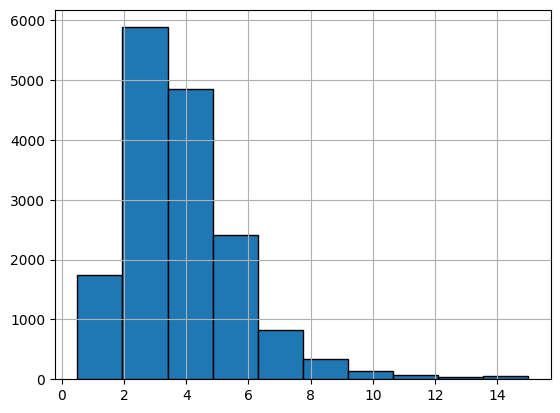

In [ ]:
X_train["median_income"].hist(edgecolor="black")
plt.show()

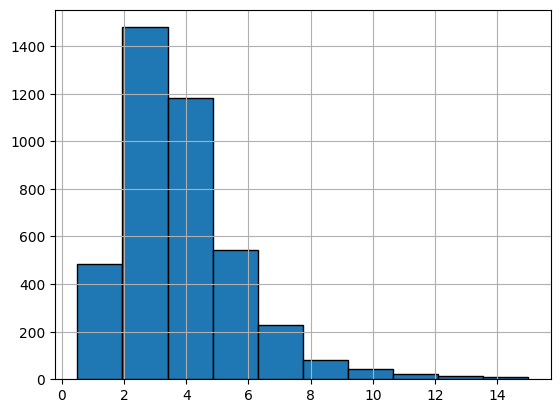

In [ ]:
X_test["median_income"].hist(edgecolor="black")
plt.show()

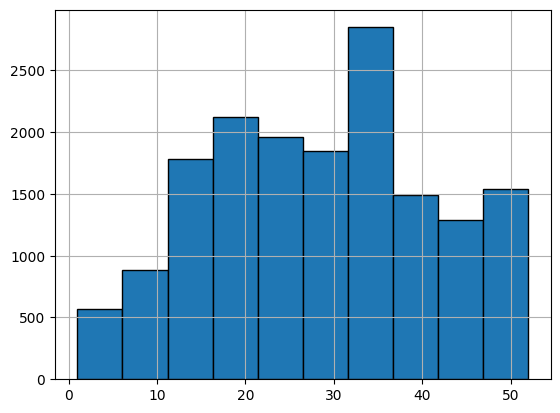

In [ ]:
X_train["housing_median_age"].hist(edgecolor="black")
plt.show()

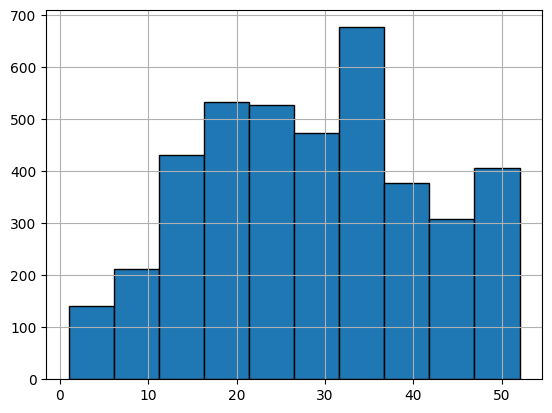

In [ ]:
X_test["housing_median_age"].hist(edgecolor="black")
plt.show()

## Entrenamiento y comparación de modelos

Se trata de un caso típico de regresión. Vamos a probar en primer lugar la **regresión lineal** (`LinearRegression`)

In [ ]:
from sklearn.linear_model import LinearRegression

# Instancia el modelo (se crea un objeto a partir de la clase que implementa el algorítmo de entrenamiento)
model_lineal = LinearRegression()

# Entrena el modelo
model_lineal.fit(X_train, y_train)

# Predicciones (en principio sobre los datos de entrenamiento)
y_pred_train = model_lineal.predict(X_train)
y_train_list = y_train.to_list()

print("Prec. real    Prec. estimado.     Error absoluto (entrenamiento)")

for i in range(20):
  r = y_train_list[i]
  e = y_pred_train[i]
  e_abs = abs(r - e)
  print(f"{r:10.2f}  {e:12.2f}  {e_abs:16.2f}")

Prec. real    Prec. estimado.     Error absoluto (entrenamiento)
 107200.00      69970.02          37229.98
 309700.00     281822.24          27877.76
 167100.00     192255.12          25155.12
 227300.00     205219.35          22080.65
 194600.00     203082.32           8482.32
 353600.00     282635.29          70964.71
 107500.00     109285.45           1785.45
  62900.00      81557.90          18657.90
 218900.00     225261.03           6361.03
 285200.00     296222.80          11022.80
 500001.00     470209.80          29791.20
 192600.00     152034.02          40565.98
  60000.00      71535.84          11535.84
 104600.00     158289.34          53689.34
 274200.00     238673.59          35526.41
 217600.00     263612.11          46012.11
  42500.00      90804.22          48304.22
 185400.00     127122.58          58277.42
 159400.00     118851.91          40548.09
 166800.00     193905.15          27105.15


Calculamos el **RMSE** y el **R²** sobre los mismos datos utilizados para entrenar el modelo.

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
r2_train = r2_score(y_train, y_pred_train)

print(f"RMSE (entrenamiento): {rmse_train:.2f}")
print(f"R² (entrenamiento): {r2_train:.2f}")

RMSE (entrenamiento): 68762.22
R² (entrenamiento): 0.64


### Validación cruzada (*cross-validation*)

La validación cruzada es una técnica que permite evaluar la capacidad de generalización de un modelo de forma más fiable que utilizando una única división de los datos.

Funciona de la siguiente manera:
1. Se divide el conjunto de entrenamiento en **K partes** de tamaño aproximadamente igual.
2. Se entrena el modelo utilizando K-1 partes y se evalúa con la parte restante.
3. Se repite el proceso K veces, utilizando cada vez una parte diferente para la validación.
4. Se calcula la media de las métricas obtenidas en las K evaluaciones.

Por ejemplo, si utilizamos **K = 5**, el modelo se entrena cinco veces, utilizando en cada ocasión el 80 % de los datos para entrenar y el 20 % restante para validar.

La validación cruzada permite comparar diferentes modelos y ajustar sus hiperparámetros sin utilizar el conjunto de prueba (*test*).

In [ ]:
from sklearn.model_selection import cross_validate

# Tres particiones mantienen razonable el tiempo de ejecución de esta primera práctica.
def evaluar_cv(modelo, nombre):
    # Evaluamos el modelo mediante validación cruzada con 3 particiones.
    # En cada iteración se entrena con 2/3 de los datos y se valida con el 1/3 restante.
    # Calculamos dos métricas: RMSE y R².
    puntuaciones = cross_validate(
        modelo, X_train, y_train, cv=3,
        scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"}
    )

    # Calculamos la media del RMSE y del R² obtenidos en las 3 iteraciones.
    # Scikit-learn devuelve el RMSE con signo negativo porque considera que
    # una puntuación mayor siempre es mejor. Cambiamos el signo para mostrarlo
    # como un error positivo (cuanto menor sea, mejor).
    rmse = -puntuaciones["test_rmse"].mean()
    r2 = puntuaciones["test_r2"].mean()

    # Mostramos las métricas medias de la validación cruzada.
    print(f"RMSE medio (validación cruzada): {rmse:.2f}")
    print(f"R² medio (validación cruzada): {r2:.3f}")

    # Devolvemos los resultados en un diccionario para poder comparar modelos.
    return {"Modelo": nombre, "RMSE CV ($)": rmse, "R² CV": r2}

resultados_cv = []
resultados_cv.append(evaluar_cv(model_lineal, "Regresión lineal"))

RMSE medio (validación cruzada): 68924.31
R² medio (validación cruzada): 0.641


Probamos con árboles de decisión.

In [ ]:
from sklearn.tree import DecisionTreeRegressor

# Instancia el modelo (se crea un objeto a partir de la clase que implementa el algorítmo de entrenamiento)
modelo_arbol = DecisionTreeRegressor()

# Entrena el modelo
modelo_arbol.fit(X_train, y_train)

# Predicciones (en principio sobre los datos de entrenamiento)
y_pred_train = modelo_arbol.predict(X_train)
y_train_list = y_train.to_list()

print("Prec. real    Prec. estimado.     Error absoluto (entrenamiento)")

for i in range(20):
  r = y_train_list[i]
  e = y_pred_train[i]
  e_abs = abs(r - e)
  print(f"{r:10.2f}  {e:12.2f}  {e_abs:16.2f}")

Prec. real    Prec. estimado.     Error absoluto (entrenamiento)
 107200.00     107200.00              0.00
 309700.00     309700.00              0.00
 167100.00     167100.00              0.00
 227300.00     227300.00              0.00
 194600.00     194600.00              0.00
 353600.00     353600.00              0.00
 107500.00     107500.00              0.00
  62900.00      62900.00              0.00
 218900.00     218900.00              0.00
 285200.00     285200.00              0.00
 500001.00     500001.00              0.00
 192600.00     192600.00              0.00
  60000.00      60000.00              0.00
 104600.00     104600.00              0.00
 274200.00     274200.00              0.00
 217600.00     217600.00              0.00
  42500.00      42500.00              0.00
 185400.00     185400.00              0.00
 159400.00     159400.00              0.00
 166800.00     166800.00              0.00


In [ ]:
# Aplicamos validación cruzada al DecisionTreeRegressor
resultados_cv.append(evaluar_cv(modelo_arbol, "Árbol de decisión"))

RMSE medio (validación cruzada): 70241.52
R² medio (validación cruzada): 0.627


Prbamos ahora con *random forest*.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Instancia el modelo (se crea un objeto a partir de la clase que implementa el algorítmo de entrenamiento)
modelo_bosque = RandomForestRegressor()
# Entrena el modelo
modelo_bosque.fit(X_train, y_train)

# Predicciones (en principio sobre los datos de entrenamiento)
y_pred_train = modelo_bosque.predict(X_train)
y_train_list = y_train.to_list()

print("Prec. real    Prec. estimado.     Error absoluto (entrenamiento)")

for i in range(20):
  r = y_train_list[i]
  e = y_pred_train[i]
  e_abs = abs(r - e)
  print(f"{r:10.2f}  {e:12.2f}  {e_abs:16.2f}")

Prec. real    Prec. estimado.     Error absoluto (entrenamiento)
 107200.00     120063.00          12863.00
 309700.00     313024.00           3324.00
 167100.00     190182.00          23082.00
 227300.00     204677.00          22623.00
 194600.00     196737.00           2137.00
 353600.00     350499.00           3101.00
 107500.00     107654.00            154.00
  62900.00      65537.00           2637.00
 218900.00     195265.00          23635.00
 285200.00     298825.00          13625.00
 500001.00     499776.99            224.01
 192600.00     196153.00           3553.00
  60000.00      59434.00            566.00
 104600.00     107290.00           2690.00
 274200.00     245363.00          28837.00
 217600.00     221445.00           3845.00
  42500.00      51828.00           9328.00
 185400.00     162768.00          22632.00
 159400.00     144064.00          15336.00
 166800.00     175674.00           8874.00


In [ ]:
# Aplicamos validación cruzada al árbol de decisión
resultados_cv.append(evaluar_cv(modelo_bosque, "Random forest"))

RMSE medio (validación cruzada): 50597.17
R² medio (validación cruzada): 0.807


In [ ]:
# Comparativa de modelos
pd.DataFrame(resultados_cv).round(2)

,Modelo,RMSE CV ($),R² CV
0,Regresión lineal,68924.31,0.64
1,Árbol de decisión,70241.52,0.63
2,Random forest,50597.17,0.81


## Ajuste de hiperparámetros

Hemos entrenado tres modelos. Ahora intentaremos mejorar el bosque aleatorio (*Random Forest*) sin utilizar el conjunto de prueba.

Un **parámetro** es un valor que el algoritmo aprende a partir de los datos. Un **hiperparámetro** se establece antes del entrenamiento y controla cómo aprende el modelo. En este caso ajustaremos:

* `n_estimators`: número de árboles del bosque.
* `max_depth`: profundidad máxima de los árboles.
* `min_samples_leaf`: número mínimo de muestras por hoja.

### GridSearchCV: búsqueda en una rejilla

`GridSearchCV` prueba todas las combinaciones de una pequeña rejilla de hiperparámetros y elige la que obtiene menor RMSE mediante validación cruzada.

**Para que esta primera práctica no sea demasiado lenta**, buscaremos hiperparámetros sobre una muestra aleatoria de 5.000 distritos **procedentes exclusivamente del conjunto de entrenamiento**. Después comprobaremos el modelo ajustado con validación cruzada sobre **todo** el conjunto de entrenamiento y lo volveremos a entrenar con todos esos datos. El conjunto de prueba permanece reservado.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Usamos una muestra de entrenamiento para acelerar la búsqueda.
# No interviene ninguna fila del conjunto de prueba.
X_busqueda = X_train.sample(n=5000, random_state=42)
y_busqueda = y_train.loc[X_busqueda.index]

rejilla = {
    "n_estimators": [20, 40],
    "max_depth": [None, 20],
    "min_samples_leaf": [1, 3]
}
busqueda_grid = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid=rejilla,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)
busqueda_grid.fit(X_busqueda, y_busqueda)

print("Mejores hiperparámetros:", busqueda_grid.best_params_)
print(f"RMSE CV durante la búsqueda: {-busqueda_grid.best_score_:,.2f} $")

# Comparamos el modelo ajustado en las MISMAS condiciones
# que los modelos anteriores: CV=3 sobre todo X_train.
modelo_bosque_ajustado = RandomForestRegressor(
    **busqueda_grid.best_params_, random_state=42, n_jobs=-1
)
resultados_cv.append(evaluar_cv(modelo_bosque_ajustado, "Random Forest ajustado"))
modelo_bosque_ajustado.fit(X_train, y_train)

Mejores hiperparámetros: {'max_depth': 20, 'min_samples_leaf': 3, 'n_estimators': 40}
RMSE CV durante la búsqueda: 55,117.24 $
RMSE medio (validación cruzada): 50766.63
R² medio (validación cruzada): 0.805


RandomForestRegressor(max_depth=20, min_samples_leaf=3, n_estimators=40,
                      n_jobs=-1, random_state=42)

## Evaluación final del modelo

Compararemos los resultados obtenidos mediante validación cruzada, elegiremos el modelo con menor RMSE y después evaluaremos una vez el modelo seleccionado sobre `X_test` e `y_test`.

In [ ]:
# Compara los modelos utilizando la misma validación cruzada.
# Incluye el modelo ajustado y evaluado con todas las filas de entrenamiento.
tabla_resultados = pd.DataFrame(resultados_cv).sort_values("RMSE CV ($)").reset_index(drop=True)
print("Comparación mediante validación cruzada (menor RMSE es mejor):")
display(tabla_resultados.round(2))

# Elegimos el mejor modelo según RMSE de validación cruzada,
# sin utilizar el test. Ajustar hiperparámetros no garantiza una mejora.
modelos = {
    "Regresión lineal": model_lineal,
    "Árbol de decisión": modelo_arbol,
    "Random forest": modelo_bosque,
    "Random Forest ajustado": modelo_bosque_ajustado
}
nombre_final = tabla_resultados.loc[0, "Modelo"] # Seleccionamos el mejor
modelo_final = modelos[nombre_final]
print("Modelo seleccionado:", nombre_final)

Comparación mediante validación cruzada (menor RMSE es mejor):


,Modelo,RMSE CV ($),R² CV
0,Random forest,50597.17,0.81
1,Random Forest ajustado,50766.63,0.81
2,Regresión lineal,68924.31,0.64
3,Árbol de decisión,70241.52,0.63


Modelo seleccionado: Random forest


## Conclusiones

Hemos recorrido las etapas principales de un proyecto de aprendizaje automático: exploración de datos, preparación, entrenamiento, comparación, ajuste de hiperparámetros y evaluación final.

* **Comparación de algoritmos.** La tabla de validación cruzada permite comparar la regresión lineal, el árbol de decisión y Random Forest. No debemos elegir un modelo por lo bien que predice sobre sus propios datos de entrenamiento: podría haber **sobreajuste**.
* **Interpretación del RMSE.** Un RMSE de, por ejemplo, 50.000 dólares indica una magnitud típica del error de predicción, penalizando más los errores grandes. **No** significa que todas las predicciones tengan un error de 50.000 dólares ni que ese sea el error absoluto medio.
* **Conjunto de prueba.** Hemos reservado el test para el final, de modo que sirva como estimación independiente del rendimiento del modelo elegido.
* **Limitaciones de los datos.** El conjunto contiene valores de vivienda limitados superiormente a 500.001 dólares y describe **precios medianos por distrito**, no el precio de cada vivienda individual. Por tanto, no permite identificar por sí solo una oportunidad real de inversión: habría que contrastar las predicciones con precios reales de oferta o compraventa.
* **Posibles mejoras.** Podríamos revisar el tratamiento de los nulos, evaluar los atributos nuevos creados en *feature engineering*, utilizar otros algoritmos o incorporar información más actual.

Por último, podemos inspeccionar qué características utiliza más un bosque aleatorio. La **importancia de las características** es orientativa: no implica una relación causal.

Importancia de las características:


,Importancia
median_income,0.479
ocean_proximity_INLAND,0.147
longitude,0.111
latitude,0.100
housing_median_age,0.054
population,0.032
total_rooms,0.025
total_bedrooms,0.022
households,0.019
ocean_proximity_NEAR OCEAN,0.007


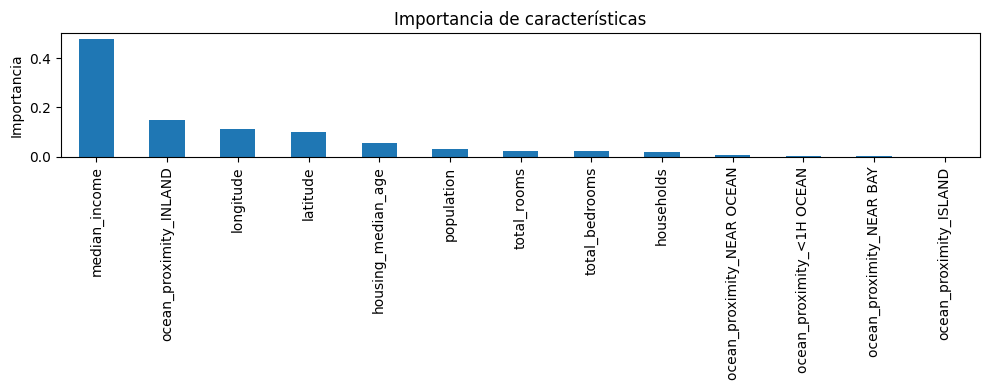

In [ ]:
# Interpretación básica del bosque aleatorio (si ha sido el elegido).
if hasattr(modelo_final, "feature_importances_"):
    importancias = pd.Series(
        modelo_final.feature_importances_, index=X_train.columns
    ).sort_values(ascending=False)
    print("Importancia de las características:")
    display(importancias.round(3).to_frame("Importancia"))
    importancias.plot.bar(figsize=(10, 4), title="Importancia de características")
    plt.ylabel("Importancia")
    plt.tight_layout()
    plt.show()
else:
    print("El modelo elegido no proporciona feature_importances_.")

## Predicción de nuevos datos

Una vez seleccionado y evaluado el modelo, podemos utilizarlo para realizar predicciones sobre nuevos distritos.

Vamos a crear tres distritos ficticios de California, indicando sus características, y utilizaremos el modelo seleccionado para estimar el precio medio de sus viviendas.

Como los datos son nuevos, no conocemos los precios reales y, por tanto, no podemos calcular el error de las predicciones.

In [ ]:
# Creamos tres distritos ficticios con las características originales.
datos_nuevos = pd.DataFrame([
    {
        "longitude": -118.24,
        "latitude": 34.05,
        "housing_median_age": 28,
        "total_rooms": 2500,
        "total_bedrooms": 450,
        "population": 1600,
        "households": 500,
        "median_income": 4.2,
        "ocean_proximity": "<1H OCEAN"
    },
    {
        "longitude": -122.42,
        "latitude": 37.77,
        "housing_median_age": 35,
        "total_rooms": 2200,
        "total_bedrooms": 400,
        "population": 1100,
        "households": 430,
        "median_income": 7.0,
        "ocean_proximity": "NEAR BAY"
    },
    {
        "longitude": -119.78,
        "latitude": 36.74,
        "housing_median_age": 24,
        "total_rooms": 2800,
        "total_bedrooms": 560,
        "population": 2000,
        "households": 620,
        "median_income": 2.6,
        "ocean_proximity": "INLAND"
    }
], index=["Distrito A", "Distrito B", "Distrito C"])

In [ ]:
X_nuevos = pd.get_dummies(datos_nuevos, columns=["ocean_proximity"], dtype=int)
X_nuevos = X_nuevos.reindex(columns=X_train.columns, fill_value=0)
precios_estimados = modelo_final.predict(X_nuevos)

resultados = pd.DataFrame({
    "Precio estimado ($)": precios_estimados
}, index=datos_nuevos.index)
display(resultados.round(2))

,Precio estimado ($)
Distrito A,181091.00
Distrito B,425501.25
Distrito C,73473.00


## Prueba con los datos de test

In [ ]:
#Predicciones sobre los datos de prueba
y_pred_test = modelo_final.predict(X_test)
y_test_list = y_test.to_list()

print("Prec. real    Prec. estimado.     Error absoluto (test)")

for i in range(20):
  r = y_test_list[i]
  e = y_pred_test[i]
  e_abs = abs(r - e)
  print(f"{r:10.2f}  {e:12.2f}  {e_abs:16.2f}")

Prec. real    Prec. estimado.     Error absoluto (entrenamiento)
 162300.00     190628.00          28328.00
 277600.00     371018.06          93418.06
  67900.00      66589.00           1311.00
 363100.00     215934.00         147166.00
 167400.00     178937.00          11537.00
 470800.00     446751.27          24048.73
 362500.00     308189.00          54311.00
 147500.00     117898.00          29602.00
 345100.00     359754.04          14654.04
 154200.00     321986.39         167786.39
 166700.00     243615.00          76915.00
 265800.00     205499.00          60301.00
 401700.00     474441.63          72741.63
  97100.00     101841.00           4741.00
 156800.00     174565.00          17765.00
  87500.00     154321.00          66821.00
 119400.00     126885.00           7485.00
 500001.00     500001.00              0.00
  65200.00      71555.00           6355.00
 184400.00     211034.00          26634.00


## Conclusiones

Hemos recorrido las etapas principales de un proyecto de aprendizaje automático: exploración de datos, preparación, entrenamiento, comparación, ajuste de hiperparámetros y evaluación final.

* **Comparación de algoritmos.** La tabla de validación cruzada permite comparar la regresión lineal, el árbol de decisión y Random Forest. No debemos elegir un modelo por lo bien que predice sobre sus propios datos de entrenamiento: podría haber **sobreajuste**.
* **Interpretación del RMSE.** Un RMSE de, por ejemplo, 50.000 dólares indica una magnitud típica del error de predicción, penalizando más los errores grandes. **No** significa que todas las predicciones tengan un error de 50.000 dólares ni que ese sea el error absoluto medio.
* **Conjunto de prueba.** Hemos reservado el test para el final, de modo que sirva como estimación independiente del rendimiento del modelo elegido.
* **Limitaciones de los datos.** El conjunto contiene valores de vivienda limitados superiormente a 500.001 dólares y describe **precios medianos por distrito**, no el precio de cada vivienda individual. Por tanto, no permite identificar por sí solo una oportunidad real de inversión: habría que contrastar las predicciones con precios reales de oferta o compraventa.
* **Posibles mejoras.** Podríamos revisar el tratamiento de los nulos, evaluar los atributos nuevos creados en *feature engineering*, utilizar otros algoritmos o incorporar información más actual.

Por último, podemos inspeccionar qué características utiliza más un bosque aleatorio. La **importancia de las características** es orientativa: no implica una relación causal.